# 07 - Safety-Event Prioritisation with an ANN

Input: four numbers describing an event (duration, people, mask issues, motion changes).
Output: one of four predefined event categories, mapped to a review priority.

> This is an **event-prioritisation model trained on synthetic data**. It does not assess any person's risk or intent.

**Concepts:** perceptron, forward propagation, activation functions, loss, backpropagation, optimiser, feature scaling.

In [1]:
# Make the project importable and use the project root as working folder
import os, sys
from pathlib import Path

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))
print("Project root:", ROOT)

Project root: e:\AI ENGINEER INTERVIEW PREPARATION\Smart-Surveillance-AI_Project


In [2]:
import numpy as np
import matplotlib.pyplot as plt
import joblib
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

from src.config import *
from src.safety_classification import load_safety_data

tf.keras.utils.set_random_seed(SEED)
X, y = load_safety_data()
print(X.shape, np.bincount(y), SAFETY_CLASSES)


(2382, 4) [605 599 606 572] ['long_group_event_demo', 'mask_observation_demo', 'movement_observation_demo', 'normal_demo']


## 1. Split and scale
The scaler is fitted on the **training set only** (otherwise test information leaks in) and saved, because the API must apply the same scaling.

In [3]:
X_tmp, X_test, y_tmp, y_test = train_test_split(X, y, test_size=0.15, stratify=y, random_state=SEED)
X_train, X_val, y_train, y_val = train_test_split(X_tmp, y_tmp, test_size=0.1765, stratify=y_tmp, random_state=SEED)
print(len(X_train), len(X_val), len(X_test))

scaler = StandardScaler().fit(X_train)
X_train_s, X_val_s, X_test_s = (scaler.transform(a).astype("float32") for a in (X_train, X_val, X_test))

joblib.dump(scaler, SAFETY_SCALER_PATH)
print("Saved scaler:", SAFETY_SCALER_PATH)

1666 358 358
Saved scaler: E:\AI ENGINEER INTERVIEW PREPARATION\Smart-Surveillance-AI_Project\models\safety_scaler.pkl


## 2. Activation functions

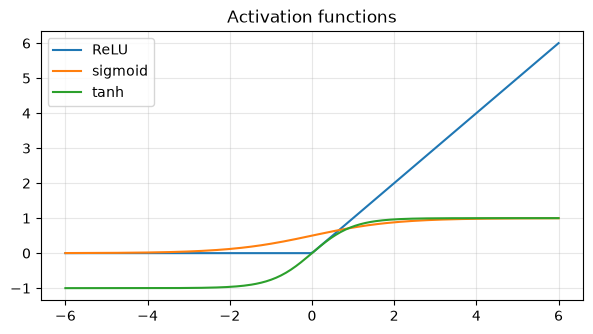

In [4]:
z = np.linspace(-6, 6, 200)
plt.figure(figsize=(7, 3.5))
plt.plot(z, np.maximum(0, z), label="ReLU")
plt.plot(z, 1 / (1 + np.exp(-z)), label="sigmoid")
plt.plot(z, np.tanh(z), label="tanh")
plt.legend(); plt.grid(alpha=0.3); plt.title("Activation functions"); plt.show()

## 3. The ANN
Two hidden layers with ReLU, softmax output for the 4 classes. Training = repeat: **forward pass** -> compute **loss** (cross-entropy) -> **backpropagation** computes gradients -> **Adam** updates the weights.


Model: "safety_ann"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense (Dense)               (None, 32)                160       
                                                                 
 dropout (Dropout)           (None, 32)                0         
                                                                 
 dense_1 (Dense)             (None, 16)                528       
                                                                 
 dense_2 (Dense)             (None, 4)                 68        
                                                                 
Total params: 756 (2.95 KB)
Trainable params: 756 (2.95 KB)
Non-trainable params: 0 (0.00 Byte)
_________________________________________________________________


epochs run: 47


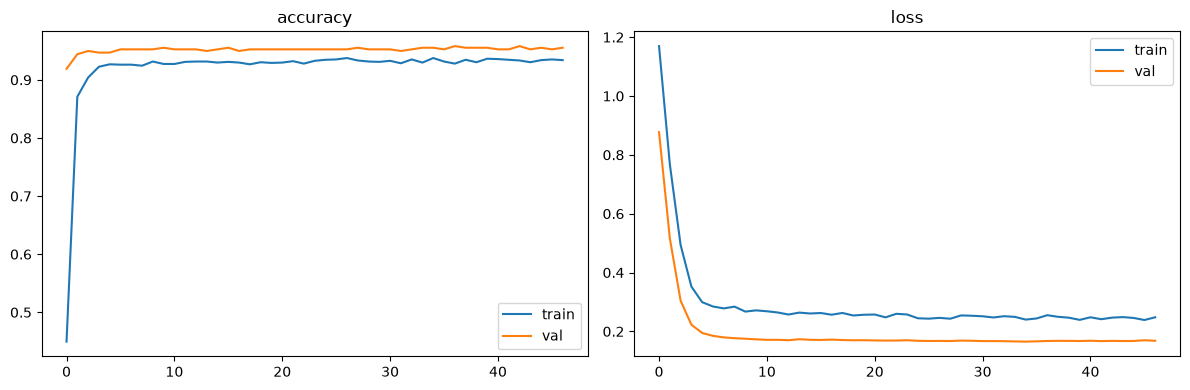

In [5]:
def build_ann():
    return keras.Sequential([
        keras.Input(shape=(len(SAFETY_FEATURES),)),
        layers.Dense(32, activation="relu"),
        layers.Dropout(0.2),
        layers.Dense(16, activation="relu"),
        layers.Dense(len(SAFETY_CLASSES), activation="softmax"),
    ], name="safety_ann")

model = build_ann()
model.compile(optimizer=keras.optimizers.Adam(1e-3),
              loss="sparse_categorical_crossentropy", metrics=["accuracy"])
model.summary()

history = model.fit(X_train_s, y_train, validation_data=(X_val_s, y_val),
                    epochs=150, batch_size=32, verbose=0,
                    callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss", patience=12, restore_best_weights=True)])
print("epochs run:", len(history.history["loss"]))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history.history["accuracy"], label="train"); axes[0].plot(history.history["val_accuracy"], label="val"); axes[0].set_title("accuracy"); axes[0].legend()
axes[1].plot(history.history["loss"], label="train"); axes[1].plot(history.history["val_loss"], label="val"); axes[1].set_title("loss"); axes[1].legend()
plt.tight_layout(); plt.show()

## 4. Evaluate and compare with a simple baseline
Labels contain ~3% deliberate noise, so a result somewhat below 100% is expected.

ANN test accuracy: 0.9665
                           precision    recall  f1-score   support

    long_group_event_demo      0.978     0.989     0.984        91
    mask_observation_demo      0.967     0.967     0.967        90
movement_observation_demo      0.978     0.967     0.972        91
              normal_demo      0.942     0.942     0.942        86

                 accuracy                          0.966       358
                macro avg      0.966     0.966     0.966       358
             weighted avg      0.966     0.966     0.966       358



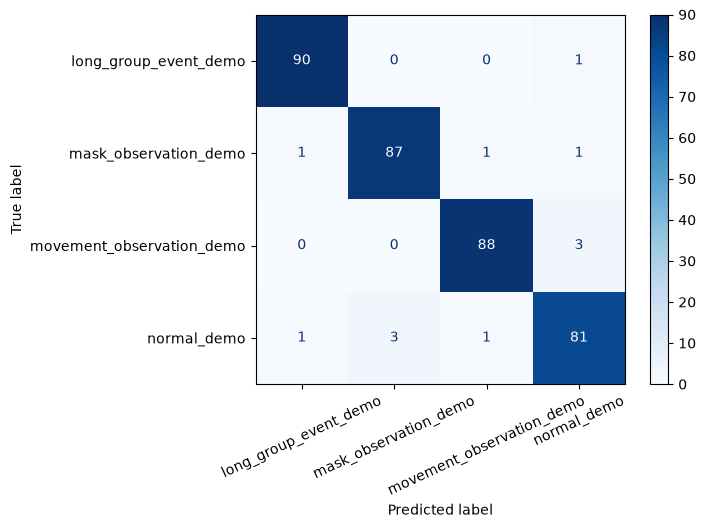

Logistic-regression baseline accuracy: 0.9553


In [6]:
y_pred = model.predict(X_test_s, verbose=0).argmax(axis=1)
print("ANN test accuracy:", round(accuracy_score(y_test, y_pred), 4))
print(classification_report(y_test, y_pred, target_names=SAFETY_CLASSES, digits=3))
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred), display_labels=SAFETY_CLASSES).plot(cmap="Blues", xticks_rotation=25)
plt.show()

baseline = LogisticRegression(max_iter=1000).fit(X_train_s, y_train)
print("Logistic-regression baseline accuracy:", round(baseline.score(X_test_s, y_test), 4))

## 5. Forward propagation by hand
Reproduce the network's output with plain NumPy to see that a neural network is just matrix multiplications plus activations.

In [7]:
W1, b1, W2, b2, W3, b3 = model.get_weights()

def forward(x):
    h1 = np.maximum(0, x @ W1 + b1)          # layer 1: linear + ReLU
    h2 = np.maximum(0, h1 @ W2 + b2)         # layer 2: linear + ReLU
    logits = h2 @ W3 + b3                    # output layer: linear
    e = np.exp(logits - logits.max(axis=1, keepdims=True))
    return e / e.sum(axis=1, keepdims=True)  # softmax

manual = forward(X_test_s[:5])
keras_out = model.predict(X_test_s[:5], verbose=0)
print("manual NumPy output == Keras output:", np.allclose(manual, keras_out, atol=1e-5))

manual NumPy output == Keras output: True


## 6. Save and test with the project's inference code

In [8]:
model.save(SAFETY_ANN_PATH)
print("Saved:", SAFETY_ANN_PATH)

from src.safety_classification import predict_safety

tests = [
    dict(duration_seconds=120, people_count=4, mask_issue_count=0, motion_change_count=3),
    dict(duration_seconds=900, people_count=14, mask_issue_count=1, motion_change_count=7),
    dict(duration_seconds=110, people_count=5, mask_issue_count=1, motion_change_count=16),
    dict(duration_seconds=150, people_count=6, mask_issue_count=5, motion_change_count=4),
]
for t in tests:
    r = predict_safety(**t)
    print(f"{r['label']:28s} priority={r['priority']:6s} conf={r['confidence']:.2f} | {t}")

Saved: E:\AI ENGINEER INTERVIEW PREPARATION\Smart-Surveillance-AI_Project\models\safety_ann.keras
normal_demo                  priority=Low    conf=0.94 | {'duration_seconds': 120, 'people_count': 4, 'mask_issue_count': 0, 'motion_change_count': 3}
long_group_event_demo        priority=Medium conf=1.00 | {'duration_seconds': 900, 'people_count': 14, 'mask_issue_count': 1, 'motion_change_count': 7}
movement_observation_demo    priority=High   conf=0.98 | {'duration_seconds': 110, 'people_count': 5, 'mask_issue_count': 1, 'motion_change_count': 16}
mask_observation_demo        priority=Medium conf=1.00 | {'duration_seconds': 150, 'people_count': 6, 'mask_issue_count': 5, 'motion_change_count': 4}


**Done:** `models/safety_ann.keras` and `models/safety_scaler.pkl` are saved. All models are trained - next is `database` usage, the FastAPI backend and the Streamlit dashboard.